<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_14_Mini_Project_End_to_End.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, json, time, warnings, os
os.environ["PYTHONWARNINGS"] = "ignore"        # juga untuk proses paralel (n_jobs=-1)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv"
kolom = ["status_rekening", "durasi_bulan", "riwayat_kredit", "tujuan", "jumlah_kredit", "tabungan",
         "lama_bekerja", "rasio_cicilan", "status_pribadi", "penjamin", "lama_tinggal", "properti",
         "usia", "cicilan_lain", "tempat_tinggal", "jumlah_kredit_berjalan", "pekerjaan", "tanggungan",
         "telepon", "pekerja_asing", "kelas"]
df = pd.read_csv(URL, header=None, names=kolom)
df["gagal_bayar"] = (df["kelas"] == 2).astype(int)      # 1 = kredit buruk (positif), 0 = baik
df = df.drop(columns="kelas")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (1000, 21)


,status_rekening,durasi_bulan,riwayat_kredit,tujuan,jumlah_kredit,tabungan,lama_bekerja,rasio_cicilan,status_pribadi,penjamin,...,properti,usia,cicilan_lain,tempat_tinggal,jumlah_kredit_berjalan,pekerjaan,tanggungan,telepon,pekerja_asing,gagal_bayar
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


In [2]:
print("Missing value total:", int(df.isnull().sum().sum()))
print("\nDistribusi target:\n", df["gagal_bayar"].value_counts().rename({0: "baik", 1: "buruk"}))
print("Proporsi buruk: %.1f%%" % (100 * df["gagal_bayar"].mean()))
df.describe().T.round(2)

Missing value total: 0

Distribusi target:
 gagal_bayar
baik     700
buruk    300
Name: count, dtype: int64
Proporsi buruk: 30.0%


,count,mean,std,min,25%,50%,75%,max
durasi_bulan,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
jumlah_kredit,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
rasio_cicilan,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
lama_tinggal,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
usia,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
jumlah_kredit_berjalan,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
tanggungan,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0
gagal_bayar,1000.0,0.30,0.46,0.0,0.0,0.0,1.00,1.0


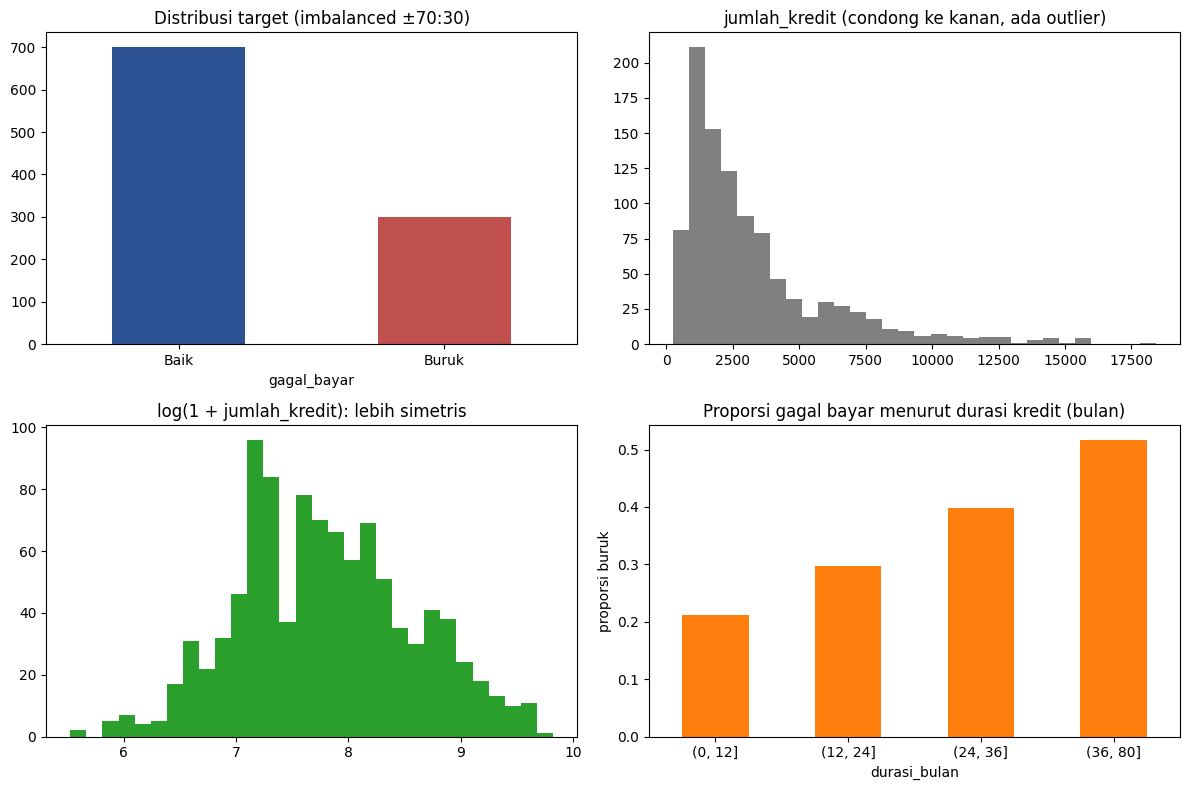

Outlier jumlah_kredit (aturan IQR): 72 data (7.2%) -> bukan kesalahan data, dipertahankan dan ditangani dengan transformasi log.

Proporsi gagal bayar menurut status_rekening:
 status_rekening      A11     A12     A13      A14
mean               0.493    0.39   0.222    0.117
size             274.000  269.00  63.000  394.000

Proporsi gagal bayar menurut riwayat_kredit:
 riwayat_kredit     A30     A31      A32     A33      A34
mean             0.625   0.571    0.319   0.318    0.171
size            40.000  49.000  530.000  88.000  293.000

Proporsi gagal bayar menurut tabungan:
 tabungan     A61     A62     A63     A64      A65
mean        0.36    0.33   0.175   0.125    0.175
size      603.00  103.00  63.000  48.000  183.000


In [3]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
df["gagal_bayar"].map({0: "Baik", 1: "Buruk"}).value_counts().plot.bar(ax=ax[0, 0], color=["#2E5395", "#C0504D"], rot=0)
ax[0, 0].set_title("Distribusi target (imbalanced ±70:30)")
ax[0, 1].hist(df["jumlah_kredit"], bins=30, color="gray"); ax[0, 1].set_title("jumlah_kredit (condong ke kanan, ada outlier)")
ax[1, 0].hist(np.log1p(df["jumlah_kredit"]), bins=30, color="tab:green"); ax[1, 0].set_title("log(1 + jumlah_kredit): lebih simetris")
df.groupby(pd.cut(df["durasi_bulan"], [0, 12, 24, 36, 80]), observed=True)["gagal_bayar"].mean().plot.bar(ax=ax[1, 1], rot=0, color="tab:orange")
ax[1, 1].set_title("Proporsi gagal bayar menurut durasi kredit (bulan)"); ax[1, 1].set_ylabel("proporsi buruk")
plt.tight_layout(); plt.show()

q1, q3 = df["jumlah_kredit"].quantile([.25, .75]); iqr = q3 - q1
n_out = int((df["jumlah_kredit"] > q3 + 1.5 * iqr).sum())
print(f"Outlier jumlah_kredit (aturan IQR): {n_out} data ({100 * n_out / len(df):.1f}%) -> bukan kesalahan data, dipertahankan dan ditangani dengan transformasi log.")
for k in ["status_rekening", "riwayat_kredit", "tabungan"]:
    print(f"\nProporsi gagal bayar menurut {k}:\n", df.groupby(k)["gagal_bayar"].agg(["mean", "size"]).round(3).T)

In [4]:
%%writefile fitur.py
import numpy as np
import pandas as pd

def tambah_fitur(df):
    # Feature engineering: dipakai di dalam Pipeline (training dan deployment memakai fungsi yang sama)
    df = df.copy()
    df["log_jumlah_kredit"] = np.log1p(df["jumlah_kredit"])
    df["cicilan_per_bulan"] = df["jumlah_kredit"] / df["durasi_bulan"].clip(lower=1)
    return df

Writing fitur.py


In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from fitur import tambah_fitur

FITUR_SENSITIF = ["status_pribadi", "pekerja_asing"]
X = df.drop(columns=["gagal_bayar"] + FITUR_SENSITIF)
y = df["gagal_bayar"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| proporsi buruk train/test:", y_train.mean().round(3), "/", y_test.mean().round(3))

fitur_num = ["durasi_bulan", "jumlah_kredit", "rasio_cicilan", "lama_tinggal", "usia", "jumlah_kredit_berjalan",
             "tanggungan", "log_jumlah_kredit", "cicilan_per_bulan"]
fitur_cat = [c for c in X.columns if c not in fitur_num and c not in ["log_jumlah_kredit", "cicilan_per_bulan"]]
print("Fitur kategorikal:", fitur_cat)

def buat_pipeline(model):
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), fitur_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), fitur_cat),
    ])
    return Pipeline([("fe", FunctionTransformer(tambah_fitur)), ("prep", prep), ("clf", model)])

Train: (800, 18) | Test: (200, 18) | proporsi buruk train/test: 0.3 / 0.3
Fitur kategorikal: ['status_rekening', 'riwayat_kredit', 'tujuan', 'tabungan', 'lama_bekerja', 'penjamin', 'properti', 'cicilan_lain', 'tempat_tinggal', 'pekerjaan', 'telepon']


In [6]:
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

model_configs = {
    "Logistic Regression": (LogisticRegression(max_iter=2000), {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
                      {"clf__max_depth": [3, 4, 5, 6, 8, None], "clf__min_samples_leaf": [1, 5, 10, 20],
                       "clf__criterion": ["gini", "entropy"]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 6, 8, None],
                       "clf__min_samples_leaf": [1, 3, 5], "clf__max_features": ["sqrt", 0.3]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
                          {"clf__n_estimators": [100, 200, 300], "clf__learning_rate": [0.03, 0.05, 0.1],
                           "clf__max_depth": [2, 3], "clf__subsample": [0.8, 1.0]}),
    "SVM (RBF)": (SVC(kernel="rbf", probability=True, random_state=42),
                  {"clf__C": [0.5, 1, 3, 10], "clf__gamma": ["scale", 0.003, 0.01, 0.03]}),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_terbaik, hasil_cv = {}, {}

# Pembanding dasar
dummy = buat_pipeline(DummyClassifier(strategy="prior")).fit(X_train, y_train)
hasil_terbaik["Dummy (mayoritas)"] = dummy

for nama, (model, params) in model_configs.items():
    n_iter = min(8, len(ParameterGrid(params)))
    t0 = time.perf_counter()
    search = RandomizedSearchCV(buat_pipeline(model), params, n_iter=n_iter, cv=skf,
                                scoring="average_precision", random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    hasil_terbaik[nama] = search.best_estimator_
    hasil_cv[nama] = search.best_score_
    print(f"{nama}: PR-AUC CV terbaik = {search.best_score_:.3f} | {time.perf_counter() - t0:.0f} dtk | "
          f"{ {k.replace('clf__', ''): v for k, v in search.best_params_.items()} }")

Logistic Regression: PR-AUC CV terbaik = 0.600 | 2 dtk | {'C': 0.1}
Decision Tree: PR-AUC CV terbaik = 0.472 | 1 dtk | {'min_samples_leaf': 20, 'max_depth': 8, 'criterion': 'gini'}
Random Forest: PR-AUC CV terbaik = 0.638 | 25 dtk | {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}
Gradient Boosting: PR-AUC CV terbaik = 0.600 | 12 dtk | {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 2, 'learning_rate': 0.05}
SVM (RBF): PR-AUC CV terbaik = 0.619 | 4 dtk | {'gamma': 0.03, 'C': 3}


In [7]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

BIAYA_FP, BIAYA_FN = 1, 5
def biaya_total(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return BIAYA_FP * fp + BIAYA_FN * fn

grid_th = np.linspace(0.05, 0.95, 91)
threshold_model = {}
for nama, mdl in hasil_terbaik.items():
    if nama.startswith("Dummy"): continue
    oof = cross_val_predict(mdl, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
    biaya = [biaya_total(y_train, (oof >= t).astype(int)) for t in grid_th]
    threshold_model[nama] = float(grid_th[int(np.argmin(biaya))])
    print(f"{nama}: threshold optimal (OOF) = {threshold_model[nama]:.2f} | biaya OOF = {min(biaya)} "
          f"(pada 0,50: {biaya_total(y_train, (oof >= .5).astype(int))})")

Logistic Regression: threshold optimal (OOF) = 0.20 | biaya OOF = 414 (pada 0,50: 779)
Decision Tree: threshold optimal (OOF) = 0.22 | biaya OOF = 489 (pada 0,50: 788)
Random Forest: threshold optimal (OOF) = 0.15 | biaya OOF = 420 (pada 0,50: 770)
Gradient Boosting: threshold optimal (OOF) = 0.12 | biaya OOF = 411 (pada 0,50: 751)
SVM (RBF): threshold optimal (OOF) = 0.18 | biaya OOF = 419 (pada 0,50: 745)


### 5.2 Evaluasi pada test set (sekali)

In [8]:
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
baris = []
proba_test = {}
for nama, mdl in hasil_terbaik.items():
    p = mdl.predict_proba(X_test)[:, 1]; proba_test[nama] = p
    th = threshold_model.get(nama, 0.5)
    pred05, pred_th = (p >= 0.5).astype(int), (p >= th).astype(int)
    baris.append({"Model": nama,
                  "PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
                  "F1 @0,5": f1_score(y_test, pred05, zero_division=0),
                  "Recall @0,5": recall_score(y_test, pred05, zero_division=0),
                  "Biaya @0,5": biaya_total(y_test, pred05),
                  "Threshold": th, "Recall @th": recall_score(y_test, pred_th, zero_division=0),
                  "Precision @th": precision_score(y_test, pred_th, zero_division=0),
                  "Biaya @th": biaya_total(y_test, pred_th)})
tabel_test = pd.DataFrame(baris).set_index("Model")
tabel_test.round(3)

,PR-AUC,ROC-AUC,"F1 @0,5","Recall @0,5","Biaya @0,5",Threshold,Recall @th,Precision @th,Biaya @th
Model,,,,,,,,,
Dummy (mayoritas),0.300,0.500,0.000,0.000,300,0.50,0.000,0.000,300
Logistic Regression,0.674,0.812,0.557,0.450,175,0.20,0.867,0.416,113
Decision Tree,0.532,0.709,0.513,0.500,177,0.22,0.717,0.381,155
Random Forest,0.694,0.800,0.580,0.483,166,0.15,0.933,0.361,119
Gradient Boosting,0.669,0.799,0.604,0.533,154,0.12,0.883,0.384,120
SVM (RBF),0.668,0.795,0.558,0.483,170,0.18,0.833,0.400,125


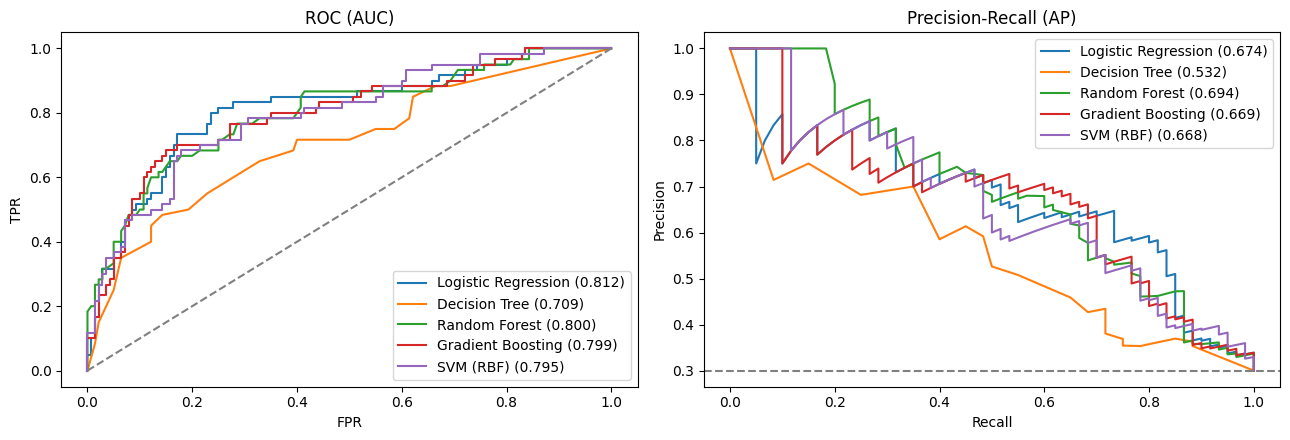

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nama, p in proba_test.items():
    if nama.startswith("Dummy"): continue
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{nama} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{nama} ({average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="gray"); ax[0].set_title("ROC (AUC)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].axhline(y_test.mean(), ls="--", color="gray"); ax[1].set_title("Precision-Recall (AP)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

In [10]:
interpretabilitas = {"Decision Tree": 5, "Logistic Regression": 4, "Random Forest": 3, "Gradient Boosting": 2, "SVM (RBF)": 2}
komposit = pd.DataFrame({"PR-AUC CV": pd.Series(hasil_cv),
                         "Interpretabilitas (1-5)": pd.Series(interpretabilitas)})
komposit["Skor gabungan"] = 0.7 * komposit["PR-AUC CV"] + 0.3 * komposit["Interpretabilitas (1-5)"] / 5
komposit = komposit.sort_values("Skor gabungan", ascending=False)
display(komposit.round(3))

nama_terpilih = komposit.index[0]
model_terpilih = hasil_terbaik[nama_terpilih]
th_terpilih = threshold_model[nama_terpilih]
print(f"Model terpilih (berdasarkan skor gabungan CV): {nama_terpilih} | threshold = {th_terpilih:.2f}")
print("\nPembanding: model dengan PR-AUC CV tertinggi saja ->", komposit['PR-AUC CV'].idxmax())

,PR-AUC CV,Interpretabilitas (1-5),Skor gabungan
Logistic Regression,0.600,4,0.660
Decision Tree,0.472,5,0.630
Random Forest,0.638,3,0.626
SVM (RBF),0.619,2,0.553
Gradient Boosting,0.600,2,0.540


Model terpilih (berdasarkan skor gabungan CV): Logistic Regression | threshold = 0.20

Pembanding: model dengan PR-AUC CV tertinggi saja -> Random Forest


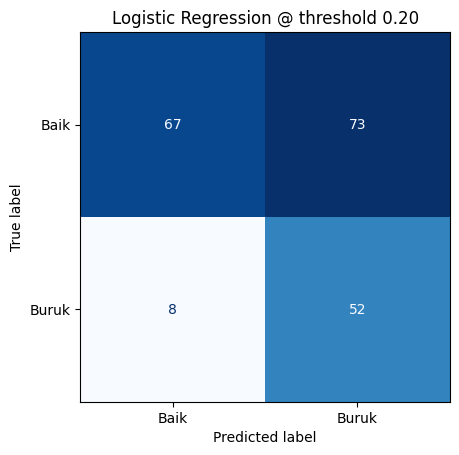

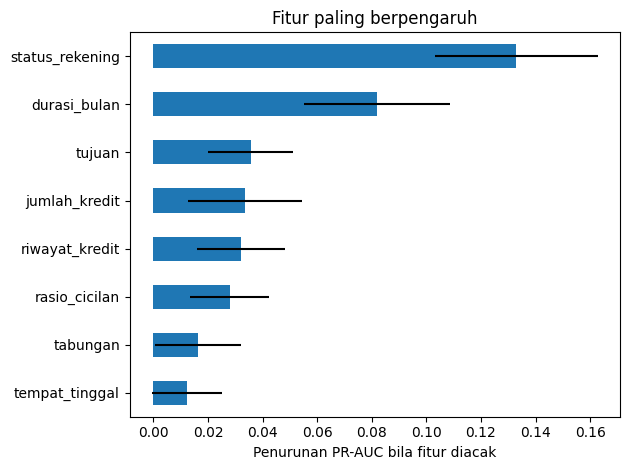

,0
status_rekening,0.1329
durasi_bulan,0.0821
tujuan,0.0357
jumlah_kredit,0.0334
riwayat_kredit,0.0322
rasio_cicilan,0.0280
tabungan,0.0164
tempat_tinggal,0.0123


In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

pred_final = (proba_test[nama_terpilih] >= th_terpilih).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final), display_labels=["Baik", "Buruk"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{nama_terpilih} @ threshold {th_terpilih:.2f}"); plt.show()

# Pentingnya fitur (permutation importance pada test set, skor PR-AUC)
pi = permutation_importance(model_terpilih, X_test, y_test, scoring="average_precision", n_repeats=15, random_state=42)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(8)[::-1].plot.barh(xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.head(8).index][::-1], color="tab:blue")
plt.xlabel("Penurunan PR-AUC bila fitur diacak"); plt.title("Fitur paling berpengaruh"); plt.tight_layout(); plt.show()
imp.head(8).round(4)

In [14]:
KAMUS = {
 "status_rekening": {"A11": "< 0 DM", "A12": "0 – 200 DM", "A13": "≥ 200 DM / gaji tetap ≥ 1 tahun", "A14": "tidak punya rekening giro"},
 "riwayat_kredit": {"A30": "tidak ada kredit / semua lunas tepat waktu", "A31": "semua kredit di bank ini lunas tepat waktu",
                    "A32": "kredit berjalan dibayar tepat waktu", "A33": "pernah terlambat membayar", "A34": "rekening kritis / kredit di bank lain"},
 "tujuan": {"A40": "mobil baru", "A41": "mobil bekas", "A42": "furnitur/peralatan", "A43": "radio/TV", "A44": "peralatan rumah tangga",
            "A45": "renovasi/perbaikan", "A46": "pendidikan", "A48": "pelatihan ulang", "A49": "usaha/bisnis", "A410": "lainnya"},
 "tabungan": {"A61": "< 100 DM", "A62": "100 – 500 DM", "A63": "500 – 1000 DM", "A64": "≥ 1000 DM", "A65": "tidak diketahui / tidak punya"},
 "lama_bekerja": {"A71": "menganggur", "A72": "< 1 tahun", "A73": "1 – 4 tahun", "A74": "4 – 7 tahun", "A75": "≥ 7 tahun"},
 "penjamin": {"A101": "tidak ada", "A102": "co-applicant", "A103": "penjamin"},
 "properti": {"A121": "tanah/bangunan", "A122": "asuransi jiwa / tabungan perumahan", "A123": "mobil/lainnya", "A124": "tidak diketahui / tidak punya"},
 "cicilan_lain": {"A141": "bank", "A142": "toko", "A143": "tidak ada"},
 "tempat_tinggal": {"A151": "sewa", "A152": "milik sendiri", "A153": "tanpa biaya (numpang)"},
 "pekerjaan": {"A171": "tidak terampil, non-penduduk", "A172": "tidak terampil, penduduk", "A173": "terampil / pegawai", "A174": "manajemen / wiraswasta / profesional"},
 "telepon": {"A191": "tidak ada", "A192": "ada (terdaftar)"},
}
LABEL_FITUR = {"durasi_bulan": "Durasi kredit (bulan)", "jumlah_kredit": "Jumlah kredit (DM)", "rasio_cicilan": "Rasio cicilan terhadap penghasilan (1–4)",
               "lama_tinggal": "Lama tinggal di alamat sekarang (1–4)", "usia": "Usia (tahun)", "jumlah_kredit_berjalan": "Jumlah kredit berjalan di bank ini",
               "tanggungan": "Jumlah tanggungan", "status_rekening": "Status rekening giro", "riwayat_kredit": "Riwayat kredit", "tujuan": "Tujuan kredit",
               "tabungan": "Tabungan/obligasi", "lama_bekerja": "Lama bekerja", "penjamin": "Penjamin / debitur lain", "properti": "Properti",
               "cicilan_lain": "Cicilan lain", "tempat_tinggal": "Tempat tinggal", "pekerjaan": "Pekerjaan", "telepon": "Telepon"}

# 1) simpan model + metadata
joblib.dump(model_terpilih, "model_terbaik.pkl")
meta = {"model": nama_terpilih, "threshold": th_terpilih, "biaya_fp": BIAYA_FP, "biaya_fn": BIAYA_FN,
        "urutan_kolom": list(X.columns),
        "numerik": {c: {"min": float(X_train[c].min()), "max": float(X_train[c].max()),
                        "default": float(X_train[c].median()), "int": bool(pd.api.types.is_integer_dtype(X_train[c]))}
                    for c in X.columns if c in fitur_num and c in X_train.columns},
        "kategorikal": {c: sorted(X_train[c].unique().tolist()) for c in fitur_cat},
        "kamus": KAMUS, "label": LABEL_FITUR}
json.dump(meta, open("model_meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Tersimpan: model_terbaik.pkl dan model_meta.json")

# 2) verifikasi: model yang dimuat ulang memberi prediksi identik
m2 = joblib.load("model_terbaik.pkl")
assert np.allclose(m2.predict_proba(X_test)[:, 1], model_terpilih.predict_proba(X_test)[:, 1])
print("Verifikasi muat ulang: prediksi identik.")

Tersimpan: model_terbaik.pkl dan model_meta.json
Verifikasi muat ulang: prediksi identik.


In [13]:
%%writefile app.py
import json
import joblib
import pandas as pd
import streamlit as st
from fitur import tambah_fitur   # dibutuhkan agar pipeline dapat dimuat

st.set_page_config(page_title="Prediksi Risiko Gagal Bayar Kredit", page_icon="💳")

@st.cache_resource
def muat():
    model = joblib.load("model_terbaik.pkl")
    meta = json.load(open("model_meta.json", encoding="utf-8"))
    return model, meta

model, meta = muat()
st.title("Prediksi Risiko Gagal Bayar Kredit")
st.caption(f"Model: {meta['model']} | Data latih: German Credit (UCI) | Aplikasi demonstrasi untuk tugas kuliah, bukan keputusan kredit sesungguhnya.")

nilai = {}
kol1, kol2 = st.columns(2)
for i, kolom in enumerate(meta["urutan_kolom"]):
    wadah = kol1 if i % 2 == 0 else kol2
    label = meta["label"].get(kolom, kolom)
    if kolom in meta["numerik"]:
        info = meta["numerik"][kolom]
        if info["int"]:
            nilai[kolom] = wadah.number_input(label, min_value=int(info["min"]), max_value=int(info["max"] * 2),
                                              value=int(info["default"]), step=1)
        else:
            nilai[kolom] = wadah.number_input(label, min_value=float(info["min"]), max_value=float(info["max"] * 2),
                                              value=float(info["default"]))
    else:
        opsi = meta["kategorikal"][kolom]
        kamus = meta["kamus"].get(kolom, {})
        nilai[kolom] = wadah.selectbox(label, opsi, format_func=lambda k, kamus=kamus: f"{kamus.get(k, k)}")

if st.button("Prediksi"):
    data_baru = pd.DataFrame([nilai])[meta["urutan_kolom"]]
    prob = float(model.predict_proba(data_baru)[0][1])
    if prob >= meta["threshold"]:
        st.error(f"Risiko TINGGI gagal bayar (probabilitas: {prob:.1%}; threshold keputusan: {meta['threshold']:.0%})")
        st.write("Rekomendasi: tinjau manual / minta jaminan tambahan sebelum menyetujui kredit.")
    else:
        st.success(f"Risiko RENDAH gagal bayar (probabilitas: {prob:.1%}; threshold keputusan: {meta['threshold']:.0%})")
        st.write("Rekomendasi: layak dilanjutkan ke proses persetujuan standar.")
    st.caption(f"Threshold dipilih meminimalkan biaya {meta['biaya_fp']}×FP + {meta['biaya_fn']}×FN pada data latih.")

Writing app.py


### Menguji aplikasi tanpa membuka browser (*headless*)

Streamlit menyediakan `AppTest` untuk menjalankan `app.py` dan memeriksa luarannya secara otomatis.

In [15]:
from streamlit.testing.v1 import AppTest
import os
at = AppTest.from_file(os.path.abspath("app.py"), default_timeout=60).run()
assert not at.exception, at.exception
at.button[0].click().run()
assert not at.exception, at.exception
hasil_ui = (at.error[0].value if at.error else at.success[0].value)
print("Keluaran aplikasi dengan nilai default:\n ", hasil_ui)

ModuleNotFoundError: No module named 'streamlit'